In [ ]:
!pip -q install ucimlrepo

import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features
y = student_performance.data.targets

df = pd.concat([X, y], axis=1)

display(df.head())

print("Dataset size:", df.shape)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Dataset size: (649, 33)


In [ ]:
df.info()

print(df.isnull().sum())

display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [ ]:
average_marks = df["G3"].mean()

print("Average final marks:", round(average_marks, 2))

Average final marks: 11.91


In [ ]:
passed_students = df[df["G3"] >= 10]

percentage = (len(passed_students) / len(df)) * 100

print("Students scoring 10 or above:",
      round(percentage, 2), "%")

Students scoring 10 or above: 84.59 %


In [ ]:
average_by_studytime = df.groupby("studytime")["G3"].mean()

print(average_by_studytime)

studytime
1    10.844340
2    12.091803
3    13.226804
4    13.057143
Name: G3, dtype: float64


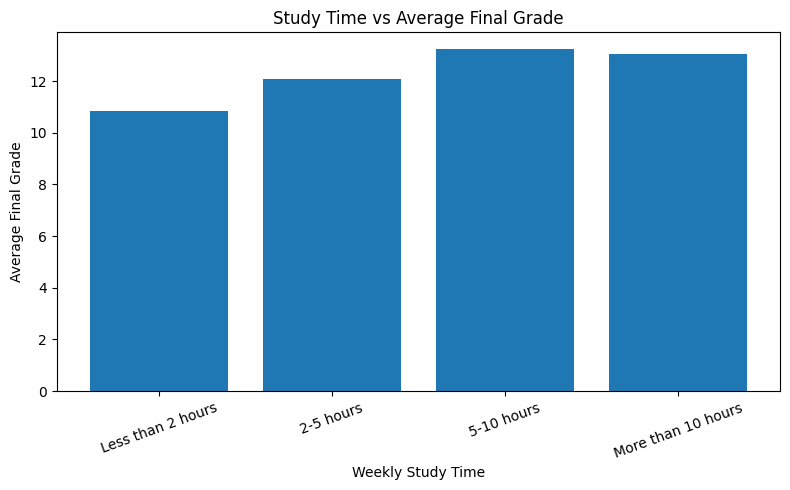

In [ ]:
study_labels = {
    1: "Less than 2 hours",
    2: "2-5 hours",
    3: "5-10 hours",
    4: "More than 10 hours"
}

average_by_studytime.index = (
    average_by_studytime.index.map(study_labels)
)

plt.figure(figsize=(8, 5))

plt.bar(
    average_by_studytime.index,
    average_by_studytime.values
)

plt.title("Study Time vs Average Final Grade")
plt.xlabel("Weekly Study Time")
plt.ylabel("Average Final Grade")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

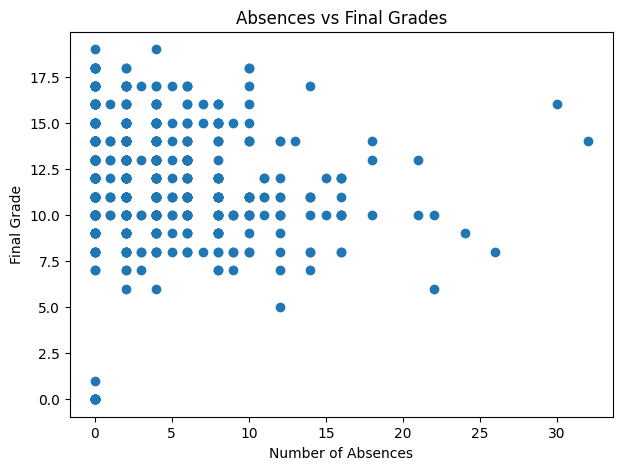

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(df["absences"], df["G3"])

plt.title("Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

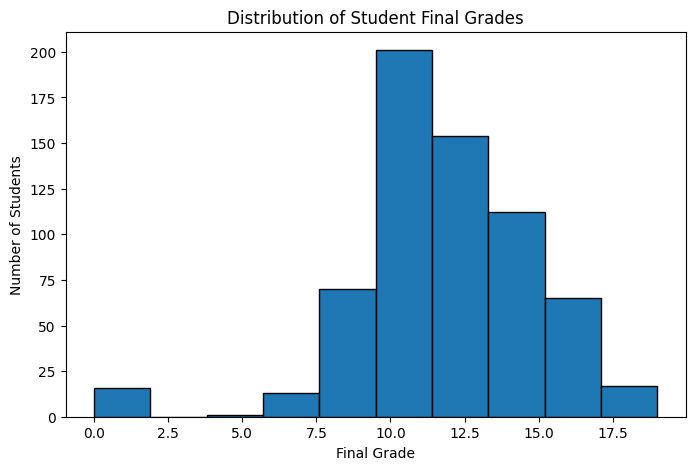

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["G3"], bins=10, edgecolor="black")

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

,studytime,absences,G1,G2,G3
studytime,1.000000,-0.118389,0.260875,0.240498,0.249789
absences,-0.118389,1.000000,-0.147149,-0.124745,-0.091379
G1,0.260875,-0.147149,1.000000,0.864982,0.826387
G2,0.240498,-0.124745,0.864982,1.000000,0.918548
G3,0.249789,-0.091379,0.826387,0.918548,1.000000


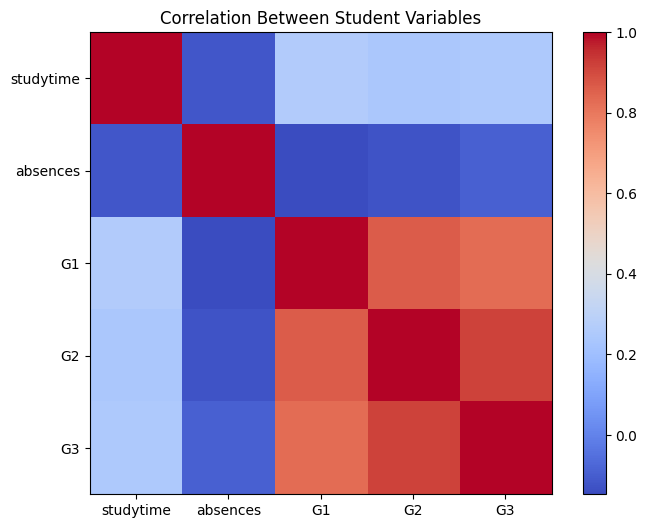

In [10]:

correlation = df[
    ["studytime", "absences", "G1", "G2", "G3"]
].corr()

display(correlation)

plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar()

plt.xticks(range(len(correlation.columns)),
           correlation.columns)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title("Correlation Between Student Variables")

plt.show()

sex
F    12.253264
M    11.406015
Name: G3, dtype: float64


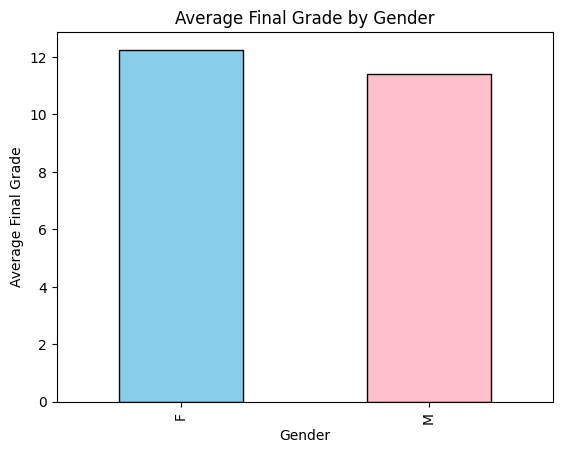

In [11]:
gender_performance = df.groupby("sex")["G3"].mean()

print(gender_performance)

gender_performance.plot(
    kind="bar",
    title="Average Final Grade by Gender",
    xlabel="Gender",
    ylabel="Average Final Grade",
    color=["skyblue", "pink"],
    edgecolor="black"
)

plt.show()